# Project Task — LSTM sequence model (hourly, leave-one-year-out CV)

> **Update (hourly + year CV + windowing).** Previously this notebook worked on **daily** Q with a
> 4-day input window and a single chronological split. It now:
> 1. Works on **hourly** Q (24-hour input window \u2192 next-hour forecast), and
> 2. Evaluates with **leave-one-year-out (LOYO) cross-validation** across the 8 study years, like
>    the LR/RF notebook, so we can report which year each model configuration performs best on.
> 3. Builds windows the way the
>    [TensorFlow time series tutorial](https://www.tensorflow.org/tutorials/structured_data/time_series)
>    does — a sliding window of consecutive timesteps predicting the next step — but **per warm-season
>    year**, since (unlike the tutorial's single continuous weather record) our record has 8 separate
>    ~7-month seasons with a hard gap between them. A window is only ever built from timestamps that
>    are truly consecutive hours; it is never allowed to splice November of one year to April of the
>    next.
> 4. Follows the tutorial's idea of encoding clock time as extra sin/cos input channels (their
>    "Day sin/cos" signal) — each window carries `q` plus `sin_hour`/`cos_hour`/`sin_doy`/`cos_doy`,
>    not just the raw discharge value.


### Step 1 — Setup

In [1]:
import os, sys
from pathlib import Path

def detect_platform() -> str:
    if 'google.colab' in sys.modules or 'COLAB_GPU' in os.environ:
        return 'colab'
    if os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
        return 'kaggle'
    return 'local'

PLATFORM = detect_platform()
if PLATFORM == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/ITEC 4000')
    print('Colab: cwd set to', os.getcwd())
else:
    print('Platform:', PLATFORM)


Platform: local


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / 'README.md').exists() and (candidate / 'data').is_dir():
        PROJECT_ROOT = candidate
        break
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from hydro_course.paths import OUTPUTS_DIR, ensure_module_dirs
from hydro_course.metrics import hydrology_metrics, regression_metrics

paths = ensure_module_dirs('module_05')
M3_FEATURES = OUTPUTS_DIR / 'module_03' / 'hy024_clean_features.csv'

INPUT_FEATURES = ['q', 'sin_hour', 'cos_hour', 'sin_doy', 'cos_doy']
INPUT_WIDTH = 24        # past 24 hours
FORECAST_HORIZON = 1    # predict the next hour
BATCH_SIZE = 128
EPOCHS = 150
PATIENCE = 8

print('TensorFlow', tf.__version__)
print('M3 features exist:', M3_FEATURES.exists())


/private/tmp/tf_test_env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow 2.20.0
M3 features exist: True


### Step 2 — Load hourly features

In [3]:
df = pd.read_csv(M3_FEATURES, index_col=0, parse_dates=True)
assert df.index.month.isin([4, 5, 6, 7, 8, 9, 10, 11]).all()

STUDY_YEARS = sorted(df['year'].unique().tolist())
print('Hourly rows:', len(df))
print('Rows per year:\n', df.groupby('year').size())


Hourly rows: 43967
Rows per year:
 year
2013    5496
2014    5496
2015    5496
2016    5495
2017    5496
2018    5496
2019    5496
2020    5496
dtype: int64


### Step 3 — Build sliding windows, one warm-season year at a time

Each year's block is verified to be a truly contiguous hourly series (no internal jump) before
windows are cut from it, so a 24-hour input window can never bridge the off-season gap between one
year and the next.


In [4]:
def make_year_windows(sub: pd.DataFrame, input_width: int, horizon: int, feature_cols: list[str]):
    sub = sub.sort_index()
    hour_diffs = sub.index.to_series().diff().iloc[1:]
    assert (hour_diffs == pd.Timedelta('1h')).all(), 'Year block is not hourly-contiguous!'

    vals = sub[feature_cols].values.astype(float)
    q_vals = sub['q'].values.astype(float)
    n = len(vals)
    end = n - input_width - horizon + 1
    X, y, target_pos = [], [], []
    for i in range(end):
        X.append(vals[i : i + input_width])
        y.append(q_vals[i + input_width + horizon - 1])
        target_pos.append(i + input_width + horizon - 1)
    X = np.asarray(X)
    y = np.asarray(y)
    target_dates = sub.index[np.asarray(target_pos)]
    return X, y, target_dates

X_parts, y_parts, date_parts, year_parts = [], [], [], []
for yv in STUDY_YEARS:
    Xy, yy, dy = make_year_windows(df[df['year'] == yv], INPUT_WIDTH, FORECAST_HORIZON, INPUT_FEATURES)
    X_parts.append(Xy); y_parts.append(yy); date_parts.append(dy)
    year_parts.append(np.full(len(yy), yv))
    print(f'{yv}: {Xy.shape[0]:,} windows')

X_all = np.concatenate(X_parts)
y_all = np.concatenate(y_parts)
years_all = np.concatenate(year_parts)
dates_all = pd.DatetimeIndex(np.concatenate([d.values for d in date_parts]))
print('\nTotal windows:', X_all.shape, '(samples, timesteps, features)')


2013: 5,472 windows
2014: 5,472 windows
2015: 5,472 windows
2016: 5,471 windows
2017: 5,472 windows
2018: 5,472 windows
2019: 5,472 windows
2020: 5,472 windows

Total windows: (43775, 24, 5) (samples, timesteps, features)


### Step 4 — Per-warm-season-year normalization (Meeting 1 rule)

Only the `q` channel needs scaling (the sin/cos channels are already bounded in [-1, 1]). As in
the LR/RF notebook, each year is standardized using its own full-season mean/std. Because windows
never cross a year boundary (Step 3), every timestep inside a given window — and its target —
belongs to the same year, so this scaling is applied consistently across an entire window.


In [5]:
year_stats = {yv: {'mu': float(df.loc[df['year'] == yv, 'q'].mean()),
                    'sigma': float(df.loc[df['year'] == yv, 'q'].std()) or 1.0}
              for yv in STUDY_YEARS}
Q_CHANNEL = INPUT_FEATURES.index('q')

def scale_X(X, years):
    out = X.astype(float).copy()
    for i, yv in enumerate(years):
        s = year_stats[yv]
        out[i, :, Q_CHANNEL] = (X[i, :, Q_CHANNEL] - s['mu']) / s['sigma']
    return out

def scale_y(y, years):
    out = y.astype(float).copy()
    for i, yv in enumerate(years):
        s = year_stats[yv]
        out[i] = (y[i] - s['mu']) / s['sigma']
    return out

def unscale_y(y, years):
    out = y.astype(float).copy()
    for i, yv in enumerate(years):
        s = year_stats[yv]
        out[i] = y[i] * s['sigma'] + s['mu']
    return out


### Step 5 — Leave-one-year-out cross-validation

For each held-out **test** year, we also need a **validation** year for early stopping (distinct
from both train and test). We use the study year immediately before the test year in `STUDY_YEARS`
(2013 wraps around to the *most recent* study year, 2020, since there is no year before it) — the
remaining 6 years are pooled for training.

This means each fold trains a fresh LSTM(64) \u2192 Dense(32, relu) \u2192 Dense(1) model on ~33k
windows; with early stopping (`PATIENCE`) this typically converges in well under `EPOCHS` epochs.


In [6]:
def build_lstm_model(input_width: int, n_features: int) -> tf.keras.Model:
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_width, n_features)),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

fold_rows = []
fold_predictions = {}
fold_histories = {}

for i, test_year in enumerate(STUDY_YEARS):
    val_year = STUDY_YEARS[i - 1]  # previous year in the list; wraps to the last year when i == 0
    train_years = [y for y in STUDY_YEARS if y not in (test_year, val_year)]

    train_mask = np.isin(years_all, train_years)
    val_mask   = years_all == val_year
    test_mask  = years_all == test_year

    X_train_s = scale_X(X_all[train_mask], years_all[train_mask])
    y_train_s = scale_y(y_all[train_mask], years_all[train_mask])
    X_val_s   = scale_X(X_all[val_mask],   years_all[val_mask])
    y_val_s   = scale_y(y_all[val_mask],   years_all[val_mask])
    X_test_s  = scale_X(X_all[test_mask],  years_all[test_mask])

    model = build_lstm_model(INPUT_WIDTH, len(INPUT_FEATURES))
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
    history = model.fit(
        X_train_s, y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
        callbacks=[early_stop], verbose=0,
    )

    y_test = y_all[test_mask]
    y_pred = unscale_y(model.predict(X_test_s, verbose=0).ravel(), years_all[test_mask])
    y_persist = X_all[test_mask][:, -1, Q_CHANNEL]  # last raw q in each test window (unscaled)

    for model_name, y_hat in [('LSTM', y_pred), ('Persistence', y_persist)]:
        fold_rows.append({'held_out_year': test_year, 'val_year': val_year, 'model': model_name,
                           'n_test': int(test_mask.sum()), **hydrology_metrics(y_test, y_hat)})

    fold_predictions[test_year] = {'dates': dates_all[test_mask], 'y_test': y_test,
                                    'y_pred': y_pred, 'y_persist': y_persist}
    fold_histories[test_year] = history.history
    print(f'test={test_year} val={val_year} train_years={train_years} '
          f'epochs_run={len(history.history["loss"])} '
          f'final val_loss={history.history["val_loss"][-1]:.4f}')

cv_results = pd.DataFrame(fold_rows)
print(cv_results.round(4).to_string(index=False))


test=2013 val=2020 train_years=[2014, 2015, 2016, 2017, 2018, 2019] epochs_run=26 final val_loss=0.1105


test=2014 val=2013 train_years=[2015, 2016, 2017, 2018, 2019, 2020] epochs_run=24 final val_loss=0.0424


test=2015 val=2014 train_years=[2013, 2016, 2017, 2018, 2019, 2020] epochs_run=14 final val_loss=0.0994


test=2016 val=2015 train_years=[2013, 2014, 2017, 2018, 2019, 2020] epochs_run=18 final val_loss=0.0587


test=2017 val=2016 train_years=[2013, 2014, 2015, 2018, 2019, 2020] epochs_run=17 final val_loss=0.1116


test=2018 val=2017 train_years=[2013, 2014, 2015, 2016, 2019, 2020] epochs_run=9 final val_loss=0.0316


test=2019 val=2018 train_years=[2013, 2014, 2015, 2016, 2017, 2020] epochs_run=9 final val_loss=0.0791


test=2020 val=2019 train_years=[2013, 2014, 2015, 2016, 2017, 2018] epochs_run=50 final val_loss=0.0650
 held_out_year  val_year       model  n_test   RMAE    MAPE    NSE    KGE
          2013      2020        LSTM    5472 0.1857 32.9164 0.9478 0.9075
          2013      2020 Persistence    5472 0.1442  5.9737 0.9496 0.9748
          2014      2013        LSTM    5472 0.1787 27.5196 0.9091 0.9155
          2014      2013 Persistence    5472 0.1898  6.6555 0.8547 0.9274
          2015      2014        LSTM    5472 0.1228 11.6927 0.9505 0.9560
          2015      2014 Persistence    5472 0.1260  4.6634 0.9287 0.9643
          2016      2015        LSTM    5471 0.1484 12.7991 0.8958 0.9183
          2016      2015 Persistence    5471 0.1420  4.8110 0.8296 0.9148
          2017      2016        LSTM    5472 0.1247 15.6572 0.9695 0.9825
          2017      2016 Persistence    5472 0.1093  5.0868 0.9570 0.9785
          2018      2017        LSTM    5472 0.1192 11.5920 0.9134 0.9514
        

### Step 6 — Best-performing held-out year

In [7]:
summary_rows = []
for model_name, g in cv_results.groupby('model'):
    best = g.loc[g['NSE'].idxmax()]
    summary_rows.append({
        'model': model_name,
        'best_year': int(best['held_out_year']),
        'best_year_NSE': best['NSE'], 'best_year_KGE': best['KGE'],
        'best_year_RMAE': best['RMAE'], 'best_year_MAPE': best['MAPE'],
        'cv_mean_NSE': g['NSE'].mean(), 'cv_std_NSE': g['NSE'].std(),
        'cv_mean_KGE': g['KGE'].mean(), 'cv_std_KGE': g['KGE'].std(),
    })
best_year_summary = pd.DataFrame(summary_rows).sort_values('cv_mean_NSE', ascending=False)
print(best_year_summary.round(4).to_string(index=False))
print()
for _, r in best_year_summary.iterrows():
    print(f"{r['model']:>12}: best on held-out {int(r['best_year'])} "
          f"(NSE={r['best_year_NSE']:.3f}, KGE={r['best_year_KGE']:.3f}); "
          f"CV mean NSE={r['cv_mean_NSE']:.3f} +/- {r['cv_std_NSE']:.3f}")


      model  best_year  best_year_NSE  best_year_KGE  best_year_RMAE  best_year_MAPE  cv_mean_NSE  cv_std_NSE  cv_mean_KGE  cv_std_KGE
       LSTM       2017         0.9695         0.9825          0.1247         15.6572       0.9210      0.0330       0.9364      0.0251
Persistence       2017         0.9570         0.9785          0.1093          5.0868       0.8875      0.0509       0.9438      0.0255

        LSTM: best on held-out 2017 (NSE=0.969, KGE=0.982); CV mean NSE=0.921 +/- 0.033
 Persistence: best on held-out 2017 (NSE=0.957, KGE=0.978); CV mean NSE=0.887 +/- 0.051


### Step 7 — CV performance across held-out years + best-year forecast

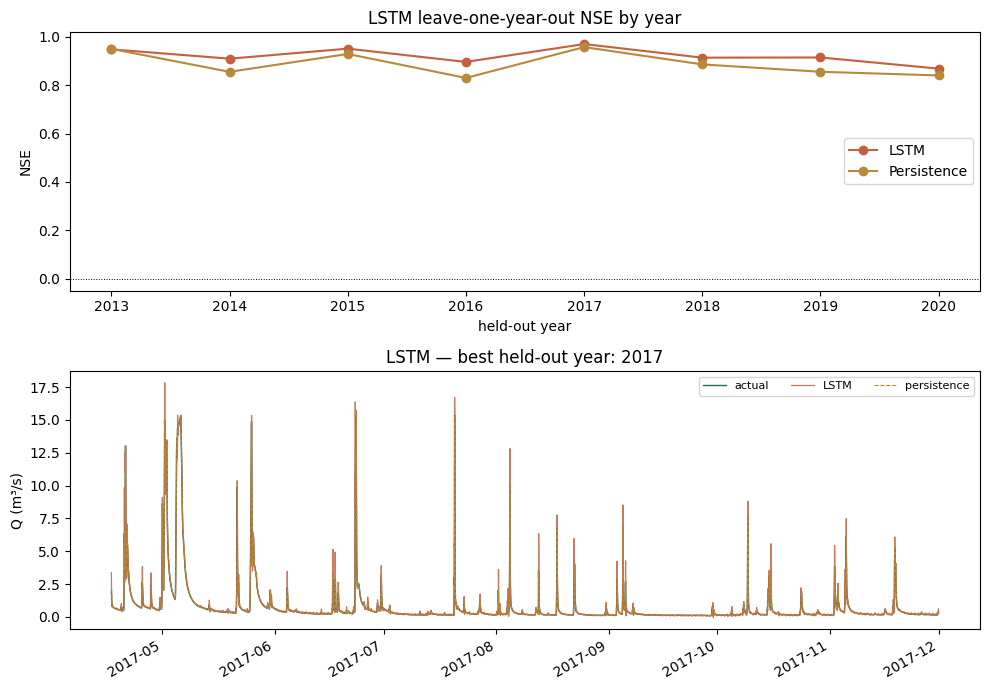

Saved -> /private/tmp/exec_root/figures/module_05/m5_lstm_cv_and_forecast.png


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

colors = {'LSTM': '#c2603f', 'Persistence': '#b8893b'}
for model_name, g in cv_results.groupby('model'):
    g = g.sort_values('held_out_year')
    axes[0].plot(g['held_out_year'], g['NSE'], marker='o', color=colors.get(model_name), label=model_name)
axes[0].axhline(0, color='black', lw=0.7, ls=':')
axes[0].set_xlabel('held-out year'); axes[0].set_ylabel('NSE')
axes[0].set_xticks(STUDY_YEARS)
axes[0].set_title('LSTM leave-one-year-out NSE by year'); axes[0].legend()

best_lstm_year = int(best_year_summary.set_index('model').loc['LSTM', 'best_year'])
fp = fold_predictions[best_lstm_year]
axes[1].plot(fp['dates'], fp['y_test'], color='#1f6f5c', lw=1.0, label='actual')
axes[1].plot(fp['dates'], fp['y_pred'], color='#c2603f', lw=0.9, alpha=0.85, label='LSTM')
axes[1].plot(fp['dates'], fp['y_persist'], color='#b8893b', lw=0.8, ls='--', label='persistence')
axes[1].set_ylabel('Q (m\u00b3/s)')
axes[1].set_title(f'LSTM \u2014 best held-out year: {best_lstm_year}')
axes[1].legend(loc='upper right', ncol=3, fontsize=8)
# Rotate only the bottom (date) axis — the top axis is a small set of whole years, not dates, and
# fig.autofmt_xdate() would otherwise blank out its tick labels too (it assumes a shared date axis).
for label in axes[1].get_xticklabels():
    label.set_rotation(30); label.set_ha('right')

fig.tight_layout()
fig_path = paths['figures'] / 'm5_lstm_cv_and_forecast.png'
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print('Saved ->', fig_path)


### Step 8 — Final model (trained on all years) + save

As in the LR/RF notebook, the CV loop exists to evaluate generalization and find the best year.
For a model to keep, we refit on as much data as possible: train on all years except the most
recent (2020 by default), which is reserved purely to drive early stopping — no test evaluation is
attached to this fit, since the CV table above already reports generalization performance.


In [9]:
final_val_year = STUDY_YEARS[-1]
final_train_years = [y for y in STUDY_YEARS if y != final_val_year]

train_mask = np.isin(years_all, final_train_years)
val_mask   = years_all == final_val_year

X_train_s = scale_X(X_all[train_mask], years_all[train_mask])
y_train_s = scale_y(y_all[train_mask], years_all[train_mask])
X_val_s   = scale_X(X_all[val_mask],   years_all[val_mask])
y_val_s   = scale_y(y_all[val_mask],   years_all[val_mask])

final_model = build_lstm_model(INPUT_WIDTH, len(INPUT_FEATURES))
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
final_history = final_model.fit(
    X_train_s, y_train_s, validation_data=(X_val_s, y_val_s),
    epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, callbacks=[early_stop], verbose=0,
)
print('Final model epochs run:', len(final_history.history['loss']),
      '| final val_loss:', round(final_history.history['val_loss'][-1], 4))

model_path = paths['models'] / 'm5_lstm.keras'
final_model.save(model_path)

cv_path = paths['outputs'] / 'm5_cv_results_by_year.csv'
cv_results.to_csv(cv_path, index=False)
summary_path = paths['outputs'] / 'm5_best_year_summary.csv'
best_year_summary.to_csv(summary_path, index=False)

record = {
    'module': 'module_05',
    'architecture': 'LSTM(64) -> Dense(32, relu) -> Dense(1)',
    'input_features': INPUT_FEATURES,
    'input_width_hours': INPUT_WIDTH,
    'forecast_horizon_hours': FORECAST_HORIZON,
    'batch_size': BATCH_SIZE,
    'epochs_max': EPOCHS,
    'early_stopping_patience': PATIENCE,
    'cv_scheme': 'leave-one-year-out test fold + rotating single-year validation fold, 6 years pooled for training',
    'scaling': 'per-warm-season-year z-score on the q channel only (Meeting 1 rule); sin/cos channels unscaled',
    'best_year_by_model': best_year_summary.set_index('model')['best_year'].to_dict(),
    'cv_mean_nse_by_model': best_year_summary.set_index('model')['cv_mean_NSE'].to_dict(),
    'final_model_train_years': final_train_years,
    'final_model_val_year': final_val_year,
}
(paths['outputs'] / 'm5_design_record.json').write_text(json.dumps(record, indent=2, default=str))
print('Saved model  ->', model_path)
print('Saved CV     ->', cv_path)
print('Saved summary->', summary_path)


Final model epochs run: 22 | final val_loss: 0.1064
Saved model  -> /private/tmp/exec_root/models/module_05/m5_lstm.keras
Saved CV     -> /private/tmp/exec_root/outputs/module_05/m5_cv_results_by_year.csv
Saved summary-> /private/tmp/exec_root/outputs/module_05/m5_best_year_summary.csv
